In [1]:
# 更新履歴
## 2026/02/25 複数のhdfファイルを読み込めるようにしました。
## 2026/02/12 作成

# 基本モジュール
import sys, os
from IPython.display import display, HTML, clear_output, update_display, Image
from tqdm import tqdm
import pyperclip
import json
from typing import Optional, Union

# データ分析用
import numpy as np
import scipy as sp
import pandas as pd
import h5py

# グラフ描画用
import matplotlib.pyplot as plt
import matplotlib as mpl
import plotly.express as px
import plotly.graph_objects as go
import PIL.Image as im

# XRDk切り開き用（不要かも）
import pyFAI

# 自作モジュール
sys.path.append(r"C:\Users\okaza\pythonenv")
from modules.Mytools.Tools import h5_tree, dict_tree, his2array, print_fileinfo, simple_progress_bar
from modules.peakfit import peakfit
import modules.Mytools.Settings

# 初期パラメーター
cachedir = os.path.join(os.getcwd(), ".cache")
os.makedirs(cachedir, exist_ok=True)
print("cache: " + os.path.abspath(cachedir))

cache: c:\Users\okaza\Documents\Documents\fpd\PeakFit\.cache


In [2]:
# ベースラインを計算する関数
def bead(signal, lam=1e6, d=2, ratio=0.01, max_iter=50):
    """
    BEAD: Baseline Estimation And Denoising
    
    Parameters
    ----------
    signal : array
        入力信号（XRD強度）
    lam : float
        平滑化パラメータ（大きいほど滑らか）
    d : int
        微分次数
    ratio : float
        非対称性パラメータ
    max_iter : int
        反復回数
        
    Returns
    -------
    baseline : array
        推定されたバックグラウンド
    """

    signal = np.asarray(signal)
    N = len(signal)

    # --- 差分行列生成 ---
    D = sp.sparse.eye(N, format='csc')
    for _ in range(d):
        D = D[1:, :] - D[:-1, :]

    H = lam * (D.T @ D)

    w = np.ones(N)

    for _ in range(max_iter):
        W = sp.sparse.diags(w, 0, shape=(N, N))
        Z = W + H

        baseline = sp.sparse.linalg.spsolve(Z, w * signal)

        diff = signal - baseline
        w = ratio * (diff > 0) + (1 - ratio) * (diff < 0)

    return baseline

## 目的

peakfit_asym_1Dprofileで出力したデータを可視化する。  
csvに保存する

## データ取得

In [3]:
# フィッティング結果が格納してあるjsonファイル
jsonfile = r"C:\Users\okaza\Documents\Documents\fpd\PeakFit\.cache\fitres.json"
# jsonfile = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\1st_compression\FPD_peakfit\fitres_UODE54_1st_200.json"

# 1D XRDが格納してあるhdfファイル
hdf_1d = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\32\UODE54_0032_integrate1d.hdf"

In [14]:
# ファイルを読み込んで、plotlyで出力する
def animation(jsonfile: str,
              hdf: str,
              ) -> None:

    # データ読み込み
    ity = []
    bg = []
    if os.path.splitext(hdf)[1] == ".hdf":
        with h5py.File(hdf, mode = "r") as f:
            tth = np.array(f["rad"][()]) # type: ignore
            for i in range(len(list(f["integrated"].keys()))): # type: ignore
                intensity = f["integrated/frame = {}".format(i)][()] # type: ignore
                baseline = bead(
                    signal = intensity,
                    lam = 1e8,
                    d = 2,
                    ratio = 0.01,
                )
                ity.append(intensity)
                bg.append(baseline)
    elif os.path.splitext(hdf)[1] == ".csv":
        df = pd.read_csv(
            r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\UODE56_0018_96-101.csv",
            header = None,
            index_col = None
        )
        tth = np.array(df[0])
        mask = (tth > 8) & (tth < 18)
        tth = tth[mask]
        intensity = np.array(df[1])[mask]
        baseline = bead(
            signal = intensity,
            lam = 1e8,
            d = 2,
            ratio = 0.01,
        )
        ity.append(intensity)
        bg.append(baseline)
            
    ity = np.vstack(ity) - np.vstack(bg)


    # jsonデータ読み込み
    with open(jsonfile, mode = "r") as f:
        d = json.load(f)
    
    # フィッティングする関数を定義
    def fit_func(tth: np.ndarray,
                 param_dict: dict,
                 function: str,
                 ) -> np.ndarray:
        
        # 値の格納先
        ity = np.zeros(tth.shape)

        # ピーク関数
        pf = peakfit()
        func = pf.psdVoigt if (function == "psdVoigt") else pf.asympsdVoigt

        # background
        dim_bg = len(param_dict["background"])
        for i in range(dim_bg):
            ity += np.power(tth-tth[0], i) * param_dict["background"]["#{}".format(i)]

        # ピーク
        n_peak = len(param_dict["peaks"])
        for i in range(n_peak):
            ity += func(tth, param_dict["peaks"]["#{}".format(i)])

        return ity
    
    # 描写するものを一括で出力する関数
    def plots(tth: np.ndarray,
              intensity: np.ndarray,
              fit_range: tuple,
              param_dict: dict,
              function: str,
              ) -> dict:
        
        # ピーク関数
        pf = peakfit()
        func = pf.psdVoigt if (function == "psdVoigt") else pf.asympsdVoigt

        # x軸
        xs = np.linspace(*fit_range, 200) # type: ignore

        # background
        dim_bg = len(param_dict["background"])
        bg = np.zeros(200)
        for i in range(dim_bg):
            bg += np.power(xs-fit_range[0], i) * param_dict["background"]["#{}".format(i)]

        # 各ピーク
        n_peak = len(param_dict["peaks"])
        peaks = []
        for i in range(n_peak):
            peak = func(xs, param_dict["peaks"]["#{}".format(i)])
            peaks.append(peak + bg)
        
        # プロフィール
        profile = fit_func(xs, param_dict, function)

        # 残差
        fit_mask = (tth > fit_range[0])*(tth < fit_range[1])
        res = intensity[fit_mask] - fit_func(tth[fit_mask], param_dict, function)

        val = {
            "masked_tth": tth[fit_mask],
            "xs": xs,
            "background": bg,
            "peaks": peaks,
            "opt": profile,
            "res": res
        }
        return val
        
    # figure作成
    if True:

        # インスタント化
        fig = go.Figure()
        trace_indices = dict()

        # 一枚目作成
        if True:
            ## データ取得
            plot_contents = plots(
                tth = tth,
                intensity = ity[0],
                fit_range = d["fitres"]["frame = 0"]["range"],
                param_dict = d["fitres"]["frame = 0"]["res"]["params"],
                function = d["func"]
            )
            ## 生データ
            raw_anim = go.Scatter(
                x = tth,
                y = ity[0],
                mode = "lines",
                line = dict(
                    color = "#1f77b4",
                    width = 1,
                ),
                name = "Raw",
            )
            fig.add_trace(raw_anim)
            trace_indices["raw_anim"] = len(fig.data) -1  # type: ignore

            ## バックグラウンド
            fit_bg = go.Scatter(
                x = plot_contents["xs"],
                y = plot_contents["background"],
                mode = "lines",
                line = dict(
                    color = "#999999",
                    width = 1,
                ),
                visible = True
            )
            fig.add_trace(fit_bg)
            trace_indices["fit_bg"] = len(fig.data)-1 # type: ignore

            ## 各ピーク
            for i in range(len(plot_contents["peaks"])):
                fit_peak = go.Scatter(
                    x = plot_contents["xs"],
                    y = plot_contents["peaks"][i],
                    mode = "lines",
                    line = dict(
                        color = "#999999",
                        width = 1,
                    ),
                    visible = True
                )
                fig.add_trace(fit_peak)
                trace_indices["fit_peak #{}".format(i)] = len(fig.data)-1 # type: ignore
            
            ## フィッティング結果
            fit_opt = go.Scatter(
                x = plot_contents["xs"],
                y = plot_contents["opt"],
                mode = "lines",
                line = dict(
                    color = "#ff770e",
                    width = 1.5,
                ),
                name = "Fit",
                visible = True
            )
            fig.add_trace(fit_opt)
            trace_indices["fit_opt"] = len(fig.data)-1 # type: ignore

            ## フィッティング結果
            fit_res = go.Scatter(
                x = plot_contents["masked_tth"],
                y = plot_contents["res"],
                mode = "lines",
                line = dict(
                    color = "#999999",
                    width = 1,
                ),
                visible = True
            )
            fig.add_trace(fit_res)
            trace_indices["fit_res"] = len(fig.data)-1 # type: ignore

        # アニメーションフレームを作成
        frame_list = []
        for k in range(ity.shape[0]):
            # データ取得
            plot_contents = plots(
                tth = tth,
                intensity = ity[k],
                fit_range = d["fitres"]["frame = {}".format(k)]["range"],
                param_dict = d["fitres"]["frame = {}".format(k)]["res"]["params"],
                function = d["func"]
            )
            frame_list.append(go.Frame(
                data = [
                    go.Scatter(
                        y = ity[k],
                    ),
                    go.Scatter(
                        x = plot_contents["xs"],
                        y = plot_contents["background"],
                    )
                ] + [
                    go.Scatter(
                        x = plot_contents["xs"],
                        y = plot_contents["peaks"][i]
                    ) for i in range(len(plot_contents["peaks"]))
                ] + [
                    go.Scatter(
                        x = plot_contents["xs"],
                        y = plot_contents["opt"]
                    ),
                    go.Scatter(
                        x = plot_contents["masked_tth"],
                        y = plot_contents["res"]
                    )
                ],
                name = str(k),
                traces = [
                    trace_indices["raw_anim"],
                    trace_indices["fit_bg"]
                ] + [
                    trace_indices["fit_peak #{}".format(i)] for i in range(len(plot_contents["peaks"]))
                ] + [
                    trace_indices["fit_opt"],
                    trace_indices["fit_res"]
                ]
            ))
        fig.frames = frame_list

        # フレーム変更用のボタンとスライダー
        updatemenus_frame = dict(
            type='buttons',
            direction = 'left', # 横並びの場合 'left', 縦並びの場合 'down'
            showactive=False,
            active = -1,
            y=0,
            x=0,
            xanchor='left',
            yanchor='top',
            pad=dict(t=65, r=0),
            buttons=[
                dict(
                    label='▶︎',
                    method='animate',
                    args=[
                        None,
                        dict(
                            frame=dict(
                                duration=50,
                                redraw=True
                            ),
                            fromcurrent=True,
                            mode='immediate',
                            transition=dict(duration=0)
                        )
                    ]
                ),
                dict(
                    label='⏸',
                    method='animate',
                    args=[
                        [None],
                        dict(
                            frame=dict(
                                duration=0,
                                redraw=False
                            ),
                            mode='immediate',
                            transition=dict(duration=0)
                        )
                    ]
                )
            ],
            visible = True
        )
        slider = dict(
            steps=[dict(
                method='animate',
                args=[
                    [str(k)],
                    dict(
                        mode='immediate',
                        frame=dict(
                            duration=0,
                            redraw=True
                            ),
                        transition=dict(
                            duration=0
                        )
                    )
                ],
                label=str(k),
            ) for k in range(ity.shape[0])],
            ticklen = 0,
            minorticklen = 0,
            active=0,
            y=0,
            x=0, # スライダーの開始位置
            len=1, # スライダーの長さ
            xanchor='left',
            yanchor='top',
            pad=dict(
                b=10,
                t=50,
                l=100
            ),
            currentvalue=dict(
                prefix='Frame = ',
                visible=True,
                xanchor='left'
            ),
            visible = True,
        )

        fig.update_layout(
            title = dict(
                text = os.path.splitext(os.path.basename(hdf))[0] if type(hdf) == str else None,
                font = dict(
                    size = 26,
                    color = "#777777"
                ),
                x = 0.05,
                y = 0.95,
                xanchor = "left",
                yanchor = "top",
            ),
            xaxis = {
                'title': "2theta [deg.]",
                "linecolor": "#000000",
                "linewidth": 1,
                'ticks': "inside",
                "tickcolor": "#000000",
                "tickwidth": 1,
                "ticklen": 5,
                'mirror': True,
            },
            yaxis = {
                'title': "Frame",
                "linecolor": "#000000",
                "linewidth": 1,
                'ticks': "inside",
                "tickcolor": "#000000",
                "tickwidth": 1,
                "ticklen": 5,
                'mirror': True,
            },
            plot_bgcolor = '#ffffff',
            updatemenus = [
                updatemenus_frame,
            ],
            sliders = [slider],
            showlegend = False,
            legend = dict(
                bordercolor = "#000000",
                orientation = "h",
                yanchor = "bottom",
                y = 1,
                bgcolor = "rgba(255,255,255,0)",
                xanchor = "center",
                x = 0.5
            ),
            width = 800,
            height = 600,
        )
        htmlfile = os.path.join(cachedir, "fitres_animation.html")
        fig.write_html(htmlfile)

        fig.show()

    return
animation(jsonfile = jsonfile, hdf = hdf_1d)
del animation


## csv出力

Save: c:\Users\okaza\Documents\Documents\fpd\PeakFit\.cache\fitres.csv


Save: c:\Users\okaza\Documents\Documents\fpd\PeakFit\.cache\fitres.png


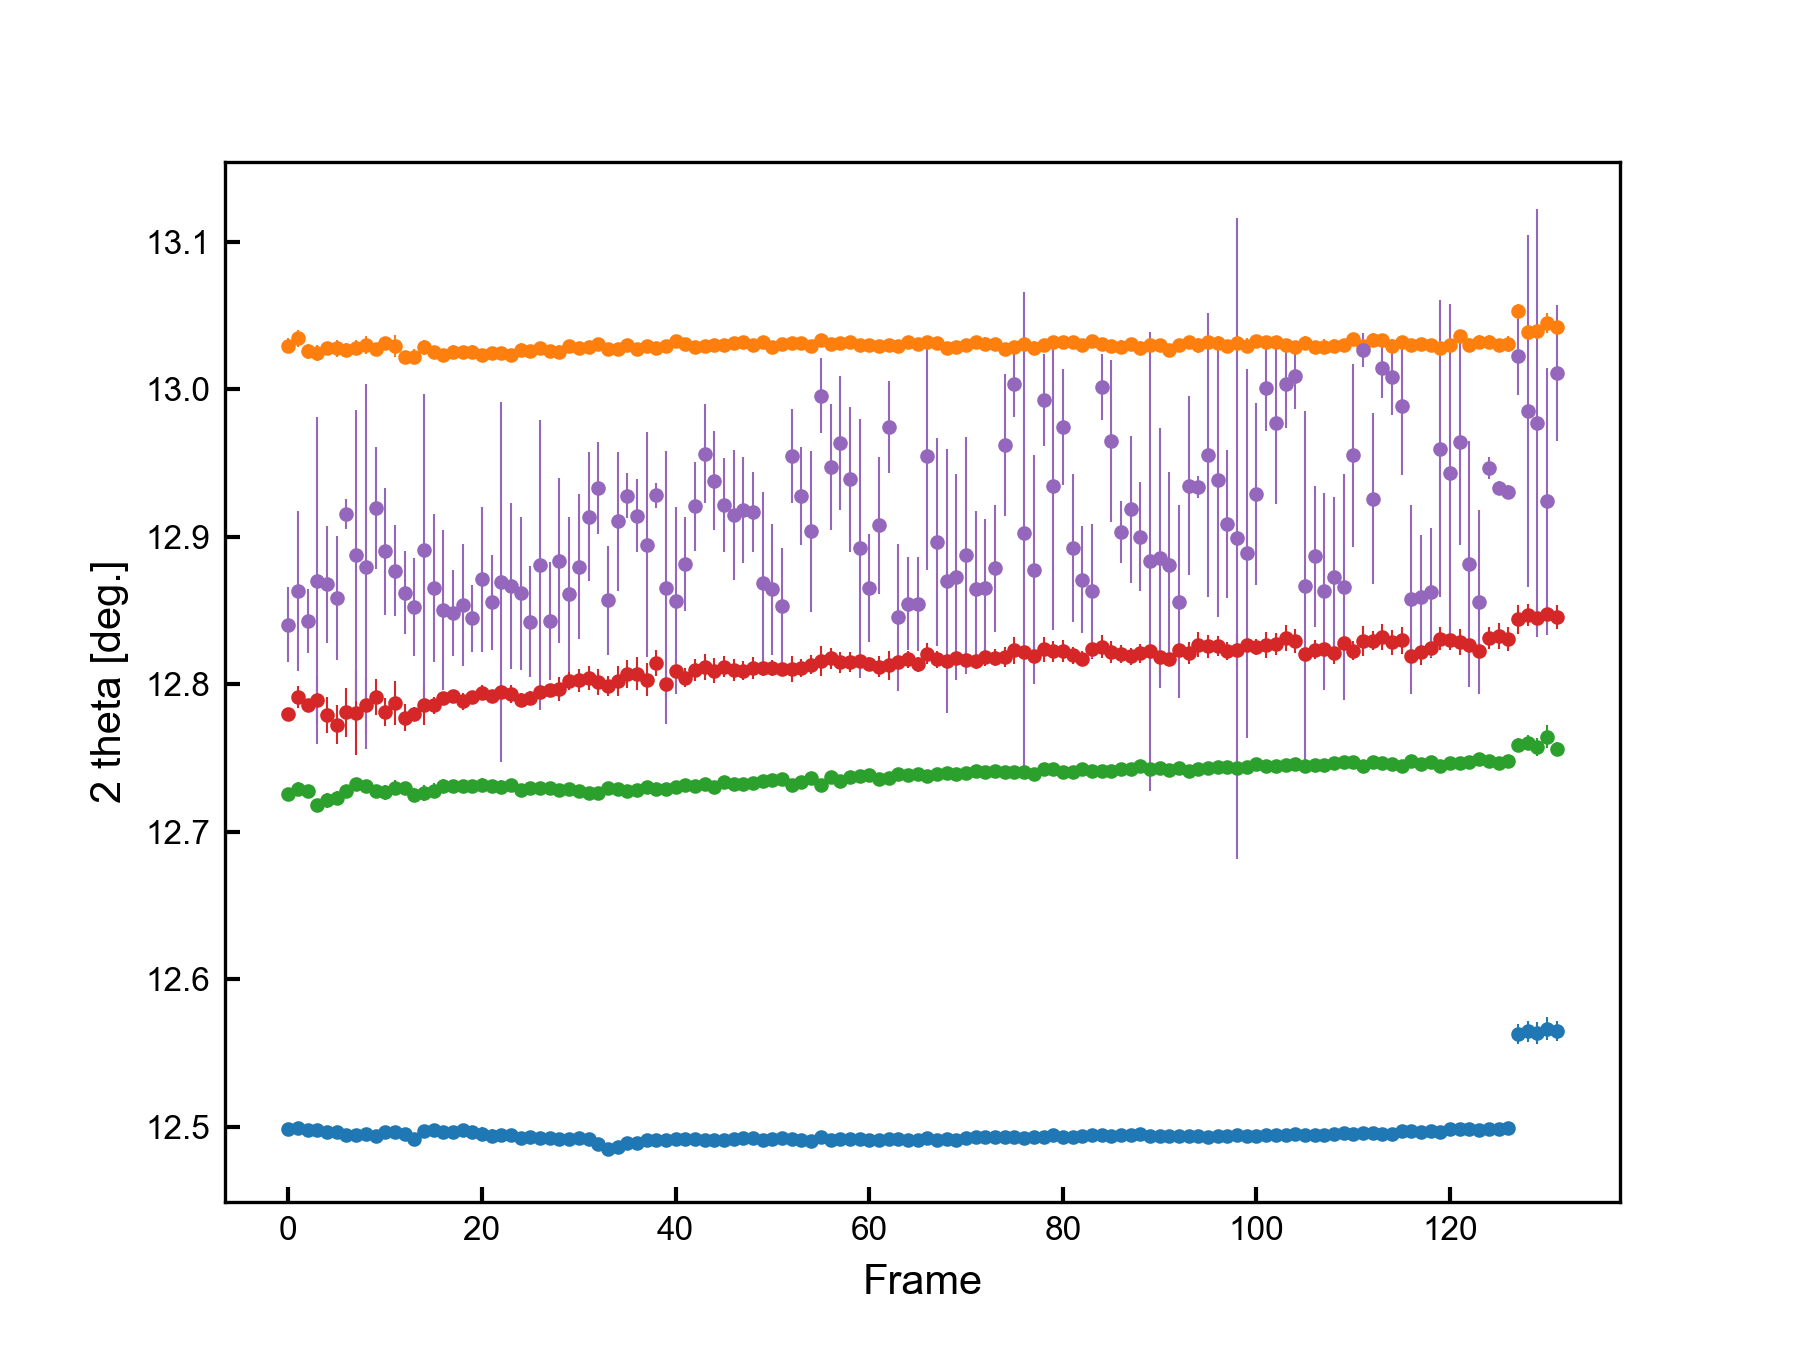

In [15]:
# figureとcsvを作成します
def makecsv(jsonfile: str,
            hdf: str,
            ) -> None:


    # データ読み込み
    ity = []
    bg = []
    if os.path.splitext(hdf)[1] == ".hdf":
        with h5py.File(hdf, mode = "r") as f:
            tth = np.array(f["rad"][()]) # type: ignore
            for i in range(len(list(f["integrated"].keys()))): # type: ignore
                intensity = f["integrated/frame = {}".format(i)][()] # type: ignore
                baseline = bead(
                    signal = intensity,
                    lam = 1e8,
                    d = 2,
                    ratio = 0.01,
                )
                ity.append(intensity)
                bg.append(baseline)
    elif os.path.splitext(hdf)[1] == ".csv":
        df = pd.read_csv(
            r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\UODE56_0018_96-101.csv",
            header = None,
            index_col = None
        )
        tth = np.array(df[0])
        mask = (tth > 8) & (tth < 18)
        tth = tth[mask]
        intensity = np.array(df[1])[mask]
        baseline = bead(
            signal = intensity,
            lam = 1e8,
            d = 2,
            ratio = 0.01,
        )
        ity.append(intensity)
        bg.append(baseline)
            
    ity = np.vstack(ity) - np.vstack(bg)


    # color code
    ccode = plt.rcParams['axes.prop_cycle'].by_key()['color']
    
    # jsonデータ読み込み
    with open(jsonfile, mode = "r") as f:
        d = json.load(f)
    
    # フィッティングする関数を定義
    def fit_func(tth: np.ndarray,
                 param_dict: dict,
                 function: str,
                 ) -> np.ndarray:
        
        # 値の格納先
        ity = np.zeros(tth.shape)

        # ピーク関数
        pf = peakfit()
        func = pf.psdVoigt if (function == "psdVoigt") else pf.asympsdVoigt

        # background
        dim_bg = len(param_dict["background"])
        for i in range(dim_bg):
            ity += np.power(tth, i) * param_dict["background"]["#{}".format(i)]

        # ピーク
        n_peak = len(param_dict["peaks"])
        for i in range(n_peak):
            ity += func(tth, param_dict["peaks"]["#{}".format(i)])

        return ity

    # ピーク数
    n_peak = len(d["fitres"]["frame = 0"]["res"]["params"]["peaks"])
    
    # フレーム
    n_frame = len(d["fitres"].keys())
    frame = np.arange(n_frame)

    # for文用の変数
    pos = []
    err = []
    pf = peakfit()
    sns = []
    if d["func"] == "asympsdVoigt":
        fitfunc = pf.asympsdVoigt
        areafunc = pf.asympsdVoigt_area
    if d["func"] == "psdVoigt":
        fitfunc = pf.psdVoigt
        areafunc = pf.psdVoigt_area

    # 位置とエラーを取得
    for i in frame:

        # データ取得
        res = d["fitres"]["frame = {}".format(i)]["res"]

        # 位置
        pos.append([res["params"]["peaks"]["#{}".format(i)]["center"] for i in range(n_peak)])

        # フィッティングエラー
        err_fit = np.array([res["error"]["peaks"]["#{}".format(i)]["center"] for i in range(n_peak)])

        # バックグラウンド
        tth_range = d["fitres"]["frame = {}".format(i)]["range"]
        tth_mask = (tth > tth_range[0]) * (tth < tth_range[1])
        y_obs = ity[i][tth_mask]
        y_opt = fit_func(tth[tth_mask], res["params"], d["func"])
        bg = np.sqrt(np.sum(np.square(y_opt - y_obs)))

        # ピーク強度
        area = np.sum([areafunc(params = res["params"]["peaks"]["#{}".format(i)]) for i in range(n_peak)])/(tth[1]-tth[0])

        # シグナルノイズ比
        sn = area / np.sqrt(area + bg)
        sns.append(sn)

        # ピークエラー
        if d["func"] == "asympsdVoigt":
            fwhm = np.array([np.mean([res["params"]["peaks"]["#{}".format(i)][side]["fwhm"] for side in ["left", "right"]]) for i in range(n_peak)])
        if d["func"] == "psdVoigt":
            fwhm = np.array([res["params"]["peaks"]["#{}".format(i)]["fwhm"] for i in range(n_peak)])
        err_peakrange = fwhm / sn

        # エラー算出
        err.append(np.sqrt(np.square(err_fit) + np.square(err_peakrange)).tolist())

    # csv保存
    pos = np.array(pos)
    err = np.array(err)
    df = pd.DataFrame(np.hstack([pos,err]), index = frame)
    df.columns = ["2 theta [deg.]"] * n_peak + ["err [deg.]"] * n_peak
    csvfile = os.path.join(cachedir, "fitres.csv")
    df.to_csv(csvfile)
    print("Save: "+ os.path.abspath(csvfile))

    if True: # plotly
        fig = go.Figure()
        
        for i in range(n_peak):
            errplot = go.Scatter(
                x=frame,
                y=pos[:,i],
                error_y=dict(
                    type='data',       # データごとに値を指定するモード
                    array=err[:,i], # エラーバーの長さのリスト
                    visible=True,      # 表示をオンにする
                    color=ccode[i%10],       # エラーバーの色
                    thickness=0.5,     # エラーバーの太さ
                    width=0            # 先端の横棒（キャップ）の幅
                ),
                mode='markers', # 点のみ表示（線をつなぐ場合は 'lines+markers'）
                marker = {
                    'symbol': "circle",
                    'size': 6,
                    'color': ccode[i%10],
                    'line': {
                        "width": 0.5,
                        "color":ccode[i%10]
                    }
                }
            )
            fig.add_trace(errplot)

        fig.update_layout(
            title = dict(
                text = os.path.splitext(os.path.basename(hdf))[0] if type(hdf) == str else None,
                font = dict(
                    size = 26,
                    color = "#777777"
                ),
                x = 0.05,
                y = 0.95,
                xanchor = "left",
                yanchor = "top",
            ),
            xaxis = {
                'title': "Frame",
                "linecolor": "#000000",
                "linewidth": 1,
                'ticks': "inside",
                "tickcolor": "#000000",
                "tickwidth": 1,
                "ticklen": 5,
                'mirror': True,
            },
            yaxis = {
                'title': "2 theta [deg.]",
                "linecolor": "#000000",
                "linewidth": 1,
                'ticks': "inside",
                "tickcolor": "#000000",
                "tickwidth": 1,
                "ticklen": 5,
                'mirror': True,
            },
            plot_bgcolor = '#ffffff',
            showlegend = False,
            legend = dict(
                bordercolor = "#000000",
                orientation = "h",
                yanchor = "bottom",
                y = 1,
                bgcolor = "rgba(255,255,255,0)",
                xanchor = "center",
                x = 0.5
            ),
            width = 800,
            height = 600,
        )

        fig.show()
        htmlfile = os.path.join(cachedir, "fitres.html")
        fig.write_html(htmlfile)
    
    if True: # matplotlib
        fig, ax = plt.subplots()
        fig.set_size_inches(6,4.5)

        for i in range(n_peak):
            ax.errorbar(
                x = frame,
                y = pos[:,i],
                yerr = err[:,i],
                lw = 0,
                fmt = "o",
                ms = 3,
                c = ccode[i%10],
                mfc = ccode[i%10],
                elinewidth=0.5,
                mew = 0.5
            )
        ax.set_xlabel("Frame", fontsize = 10)
        ax.set_ylabel("2 theta [deg.]", fontsize = 10)


        pngfile = os.path.join(cachedir, "fitres.png")
        plt.savefig(pngfile, dpi = 300)
        plt.close()
        print("Save: " + os.path.abspath(pngfile))
        display(Image(pngfile, width = 600))
    
    return
makecsv(jsonfile=jsonfile, hdf = hdf_1d)
del makecsv